Epoch 1/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 362.7831
Epoch 2/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 293.1158
Epoch 3/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 285.2983
Epoch 4/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 280.7772
Epoch 5/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 277.5605


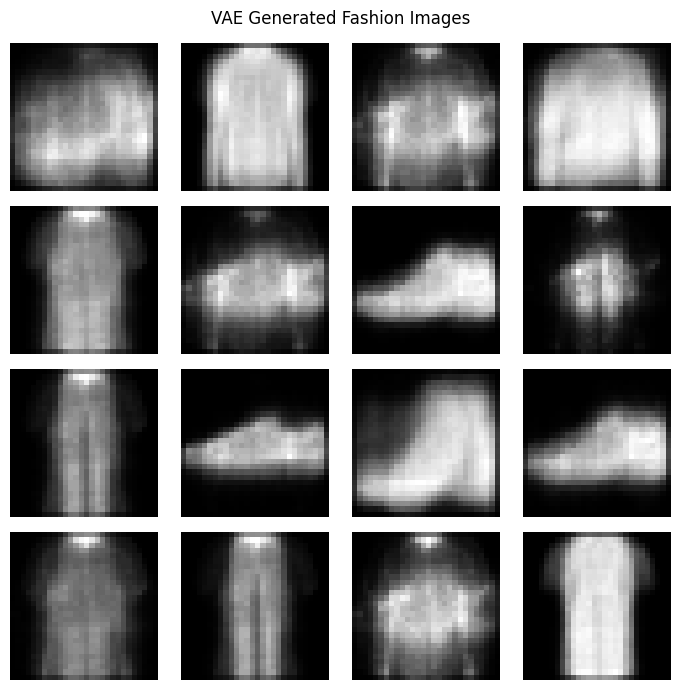

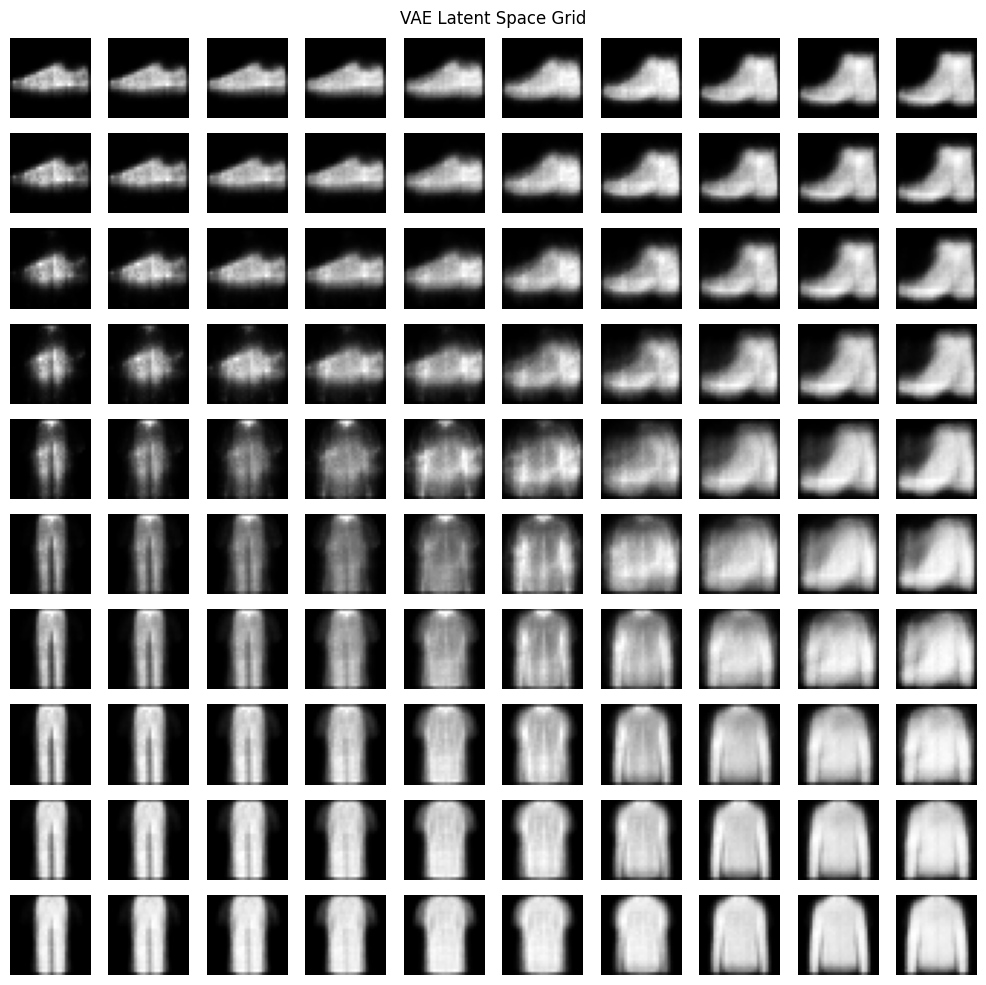

Epoch 1/5 | Generator Loss: 1.0804 | Discriminator Loss: 0.8975


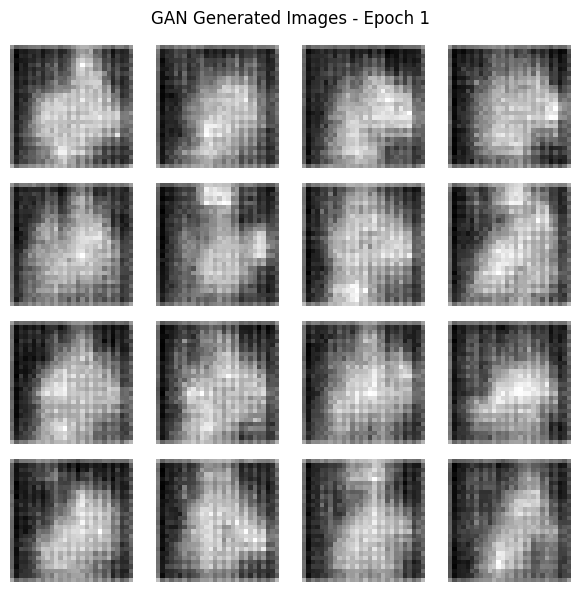

Epoch 2/5 | Generator Loss: 1.0153 | Discriminator Loss: 0.9195


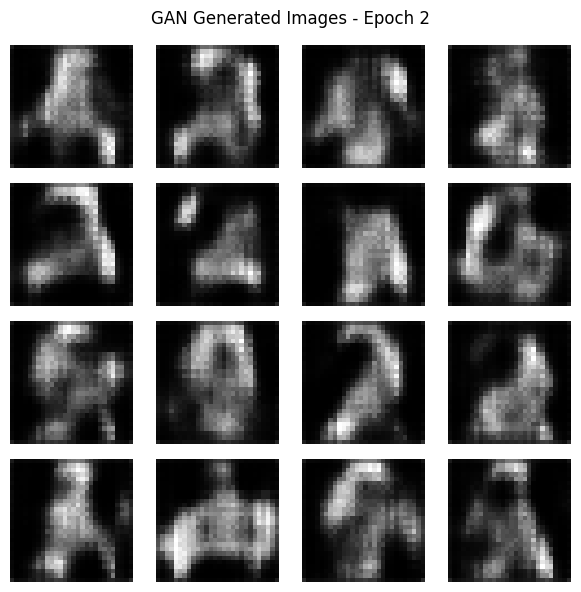

Epoch 3/5 | Generator Loss: 0.9450 | Discriminator Loss: 1.1251


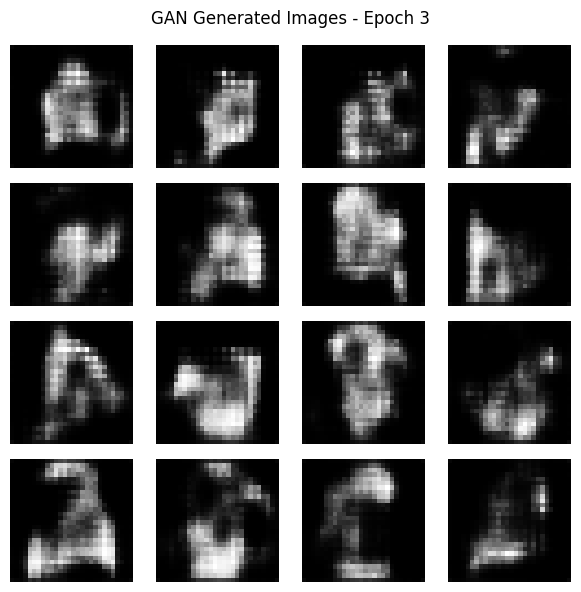

Epoch 4/5 | Generator Loss: 0.8856 | Discriminator Loss: 1.2106


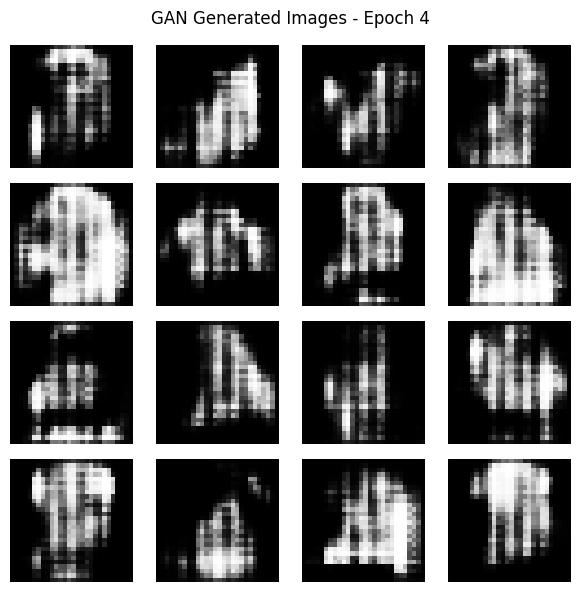

Epoch 5/5 | Generator Loss: 0.8714 | Discriminator Loss: 1.2397


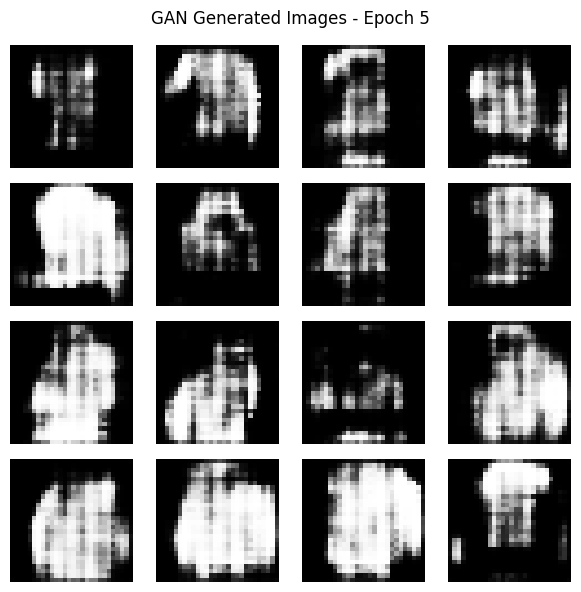

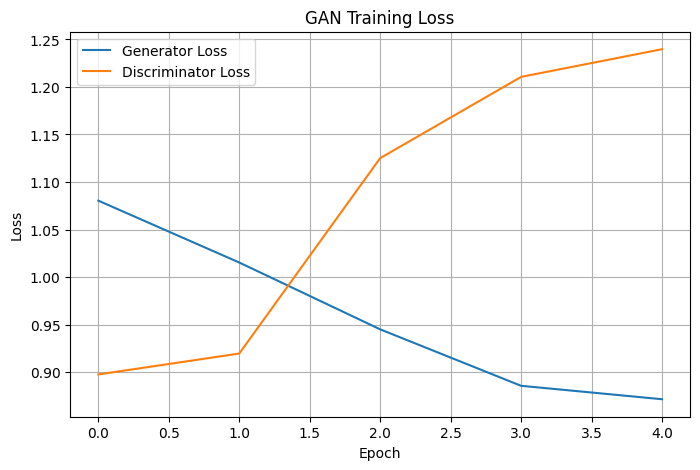

VAE and GAN generators saved successfully.


In [23]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

from tensorflow.keras import layers, Model

tf.random.set_seed(42)
np.random.seed(42)

# Load Fashion-MNIST
(x_train, _), (_, _) = tf.keras.datasets.fashion_mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_train = x_train[..., np.newaxis]

# Use subset for faster Colab training
x_train = x_train[:12000]

# ==========================
# 1. VARIATIONAL AUTOENCODER
# ==========================

latent_dim = 2

# Encoder
encoder_input = layers.Input(shape=(28, 28, 1))
x = layers.Flatten()(encoder_input)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dense(128, activation="relu")(x)

z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)

def sampling(args):
    mean, log_var = args
    epsilon = tf.random.normal(shape=tf.shape(mean))
    return mean + tf.exp(0.5 * log_var) * epsilon

z = layers.Lambda(sampling)([z_mean, z_log_var])

encoder = Model(encoder_input, [z_mean, z_log_var, z])

# Decoder
decoder_input = layers.Input(shape=(latent_dim,))
x = layers.Dense(128, activation="relu")(decoder_input)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dense(784, activation="sigmoid")(x)
decoder_output = layers.Reshape((28, 28, 1))(x)

decoder = Model(decoder_input, decoder_output)

# VAE training model
class VAE(Model):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.loss_tracker = tf.keras.metrics.Mean(name="loss")

    @property
    def metrics(self):
        return [self.loss_tracker]

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:
            mean, log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)

            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    tf.keras.losses.binary_crossentropy(data, reconstruction),
                    axis=(1, 2)
                )
            )

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + log_var - tf.square(mean) - tf.exp(log_var),
                    axis=1
                )
            )

            loss = reconstruction_loss + kl_loss

        gradients = tape.gradient(loss, self.trainable_weights)
        self.optimizer.apply_gradients(
            zip(gradients, self.trainable_weights)
        )

        self.loss_tracker.update_state(loss)
        return {"loss": self.loss_tracker.result()}

vae = VAE(encoder, decoder)
vae.compile(optimizer=tf.keras.optimizers.Adam())

vae_history = vae.fit(
    x_train,
    epochs=5,
    batch_size=128,
    verbose=1
)

# Save VAE decoder
decoder.save("/content/vae_generator.keras")

# Generate VAE samples
z_samples = np.random.normal(size=(16, latent_dim)).astype("float32")
vae_images = decoder.predict(z_samples, verbose=0)

fig, ax = plt.subplots(4, 4, figsize=(7, 7))

for i, a in enumerate(ax.ravel()):
    a.imshow(vae_images[i].squeeze(), cmap="gray")
    a.axis("off")

plt.suptitle("VAE Generated Fashion Images")
plt.tight_layout()
plt.show()

# Plot 2D latent-space grid
grid_x = np.linspace(-2, 2, 10)
grid_y = np.linspace(-2, 2, 10)

grid = np.array([[x, y] for y in grid_y for x in grid_x])
grid_images = decoder.predict(grid.astype("float32"), verbose=0)

fig, ax = plt.subplots(10, 10, figsize=(10, 10))

for i, a in enumerate(ax.ravel()):
    a.imshow(grid_images[i].squeeze(), cmap="gray")
    a.axis("off")

plt.suptitle("VAE Latent Space Grid")
plt.tight_layout()
plt.show()

# ==========================
# 2. DEEP CONVOLUTIONAL GAN
# ==========================

noise_dim = 100

# Generator
generator_input = layers.Input(shape=(noise_dim,))
x = layers.Dense(7 * 7 * 128, use_bias=False)(generator_input)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Reshape((7, 7, 128))(x)

x = layers.Conv2DTranspose(
    64, 4, strides=2, padding="same", use_bias=False
)(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(0.2)(x)

x = layers.Conv2DTranspose(
    1, 4, strides=2, padding="same", activation="sigmoid"
)(x)

generator = Model(generator_input, x)

# Discriminator
discriminator_input = layers.Input(shape=(28, 28, 1))
x = layers.Conv2D(64, 4, strides=2, padding="same")(discriminator_input)
x = layers.LeakyReLU(0.2)(x)
x = layers.Dropout(0.3)(x)

x = layers.Conv2D(128, 4, strides=2, padding="same")(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Dropout(0.3)(x)

x = layers.Flatten()(x)
discriminator_output = layers.Dense(1, activation="sigmoid")(x)

discriminator = Model(discriminator_input, discriminator_output)

# GAN training setup
cross_entropy = tf.keras.losses.BinaryCrossentropy()

generator_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)

batch_size = 128
epochs = 5

generator_losses = []
discriminator_losses = []

@tf.function
def train_step(real_images):
    noise = tf.random.normal((tf.shape(real_images)[0], noise_dim))

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        gen_loss = cross_entropy(
            tf.ones_like(fake_output), fake_output
        )

        real_loss = cross_entropy(
            tf.ones_like(real_output), real_output
        )

        fake_loss = cross_entropy(
            tf.zeros_like(fake_output), fake_output
        )

        disc_loss = real_loss + fake_loss

    gen_gradients = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )

    disc_gradients = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss

# Train GAN
dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(10000).batch(batch_size, drop_remainder=True)

for epoch in range(epochs):
    gen_epoch_loss = []
    disc_epoch_loss = []

    for batch in dataset:
        gl, dl = train_step(batch)
        gen_epoch_loss.append(float(gl))
        disc_epoch_loss.append(float(dl))

    generator_losses.append(np.mean(gen_epoch_loss))
    discriminator_losses.append(np.mean(disc_epoch_loss))

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Generator Loss: {generator_losses[-1]:.4f} | "
        f"Discriminator Loss: {discriminator_losses[-1]:.4f}"
    )

    # Save generated images after each epoch
    noise = tf.random.normal((16, noise_dim))
    generated = generator(noise, training=False).numpy()

    fig, ax = plt.subplots(4, 4, figsize=(6, 6))

    for i, a in enumerate(ax.ravel()):
        a.imshow(generated[i].squeeze(), cmap="gray")
        a.axis("off")

    plt.suptitle(f"GAN Generated Images - Epoch {epoch+1}")
    plt.tight_layout()
    plt.show()

# Save GAN generator
generator.save("/content/gan_generator.keras")

# Plot loss curves
plt.figure(figsize=(8, 5))
plt.plot(generator_losses, label="Generator Loss")
plt.plot(discriminator_losses, label="Discriminator Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid()
plt.show()

print("VAE and GAN generators saved successfully.")